# PINN — Couette No Estacionario: Barrido Paramétrico de TAU_RAMP y nu

Navier-Stokes a resolver:

$$\frac{\partial u}{\partial t} = \nu\,\frac{\partial^2 u}{\partial y^2}, \qquad y\in[0,1],\; t\in[0,T]$$

Se barren:
- **TAU_RAMP**: 0.2, 0.5, 1.0
- **nu**: 0.1, 0.3, 0.5

Para cada combinación se muestran:
1. Perfiles de velocidad u(y, t) para distintos instantes t
2. Error final L∞ vs. solución de referencia por diferencias finitas

## Imports

In [10]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap


from neurodiffeq import diff
from neurodiffeq.solvers import Solver2D
from neurodiffeq.conditions import IBVP1D
from neurodiffeq.networks import FCNN
from neurodiffeq.generators import Generator2D

C:\Users\carlo\anaconda3\Lib\site-packages\torch\__init__.py:1323: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


## Función de referencia por diferencias finitas

In [ ]:
def couette_fd_profile(t_target, nu, tau, y_max=1.0, n_y=201):
    if t_target <= 0:
        return np.linspace(0, y_max, n_y), np.zeros(n_y)
    y  = np.linspace(0, y_max, n_y)
    dy = y[1] - y[0]
    dt = 0.4 * dy**2 / nu
    n_steps = max(1, int(np.ceil(t_target / dt)))
    dt = t_target / n_steps
    r  = nu * dt / dy**2
    u = np.zeros(n_y)
    for step in range(1, n_steps + 1):
        t = step * dt
        u_new = u.copy()
        u_new[1:-1] = u[1:-1] + r * (u[2:] - 2.0 * u[1:-1] + u[:-2])
        u_new[0]  = 0.0
        u_new[-1] = 1.0 - np.exp(-t / tau)
        u = u_new
    return y, u

## Función que entrena y evalúa una PINN para (TAU_RAMP, nu)

In [ ]:
def run_pinn(tau, nu, T_MAX=5, max_epochs=10000,  callbacks=()):
    """Entrena una PINN para los parámetros dados y devuelve la solución."""

    def pde(u, y, t):
        return diff(u, t) - nu * diff(u, y, order=2)

    condition = IBVP1D(
        x_min=0, x_min_val=lambda t: torch.zeros_like(t),
        x_max=1, x_max_val=lambda t: 1 - torch.exp(-t / tau),
        t_min=0, t_min_val=lambda y: torch.zeros_like(y)
    )

    net = FCNN(
        n_input_units=2,
        n_output_units=1,
        hidden_units=(32, 32),
        actv=nn.SiLU,
    )

    train_gen = Generator2D(
        grid=(64, 64), xy_min=(0.0, 0.0), xy_max=(1.0, T_MAX),
        method='equally-spaced-noisy'
    )
    valid_gen = Generator2D(
        grid=(32, 32), xy_min=(0.0, 0.0), xy_max=(1.0, T_MAX),
        method='equally-spaced'
    )

    solver = Solver2D(
        pde_system=pde,
        conditions=[condition],
        xy_min=(0.0, 0.0),
        xy_max=(1.0, T_MAX),
        nets=[net],
        train_generator=train_gen,
        valid_generator=valid_gen,
    )

    for param_group in solver.optimizer.param_groups:
        param_group['lr'] = 1e-4

    solver.fit(max_epochs=max_epochs)
    solution = solver.get_solution(best=True)
    return solution

## Configuración del barrido paramétrico

In [ ]:
TAU_VALUES = [0.2, 0.5, 1.0]
NU_VALUES  = [0.1, 0.3, 0.5]
T_MAX      = 5

# Instantes de evaluación para los perfiles
T_EVAL = [0.1, 0.3, 0.5, 1.0, 2.0, T_MAX]

y_test = np.linspace(0, 1, 100)

## Barrido sobre TAU_RAMP (nu fijo = 0.1)

Se muestra el efecto del tiempo de arranque de la placa superior.

In [ ]:
NU_FIXED = 0.1

def print_progress(solver):
    if solver.global_epoch % 100 == 0 or solver.global_epoch == 1:
        tl = solver.metrics_history['train_loss'][-1]
        vl = solver.metrics_history['valid_loss'][-1]
        print(f"    Época {solver.global_epoch:5d} | train_loss={tl:.3e} | valid_loss={vl:.3e}")

cmap_morado_rojo = LinearSegmentedColormap.from_list('morado_rojo', ['#6A0DAD', '#ff1600'])

fig, axes = plt.subplots(1, len(TAU_VALUES), figsize=(5 * len(TAU_VALUES), 5), sharey=True)
errors_tau = {}

for ax, tau in zip(axes, TAU_VALUES):
    print(f"\n=== TAU_RAMP = {tau}, nu = {NU_FIXED} ===")
    solution = run_pinn(tau=tau, nu=NU_FIXED, T_MAX=T_MAX, callbacks=[print_progress])

    # Perfiles de velocidad
    colors = cmap_morado_rojo(np.linspace(0, 1, len(T_EVAL)))
    for t_val, color in zip(T_EVAL, colors):
        t_arr  = np.full_like(y_test, t_val)
        u_pred = solution(y_test, t_arr, to_numpy=True).flatten()
        ax.plot(u_pred, y_test, color=color, label=f't = {t_val:.2f}')

    ax.set_xlabel('u(y, t)')
    ax.set_title(f'TAU_RAMP = {tau}\nnu = {NU_FIXED}')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

    # Errores L∞ para cada t
    errs = {}
    print("  Errores L_inf vs. diferencias finitas:")
    for t_val in T_EVAL:
        t_arr        = np.full_like(y_test, t_val)
        u_pred       = solution(y_test, t_arr, to_numpy=True).flatten()
        y_ref, u_ref_grid = couette_fd_profile(t_val, NU_FIXED, tau)
        u_ref        = np.interp(y_test, y_ref, u_ref_grid)
        err          = np.max(np.abs(u_pred - u_ref))
        errs[t_val]  = err
        print(f"    t = {t_val:5.2f}   max|u_pred - u_ref| = {err:.3e}")
    errors_tau[tau] = errs

axes[0].set_ylabel('y (entre placas)')
fig.suptitle(f'Perfiles de velocidad — Barrido TAU_RAMP (nu = {NU_FIXED})', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Error final L∞ por cada TAU_RAMP (resumen)

In [ ]:
print(f"\nError final L_inf en t = {T_MAX} — Barrido TAU_RAMP (nu = {NU_FIXED}):")
print(f"{'TAU_RAMP':>10} | {'Error L_inf':>12}")
print("-" * 26)
for tau in TAU_VALUES:
    print(f"{tau:>10.2f} | {errors_tau[tau][T_MAX]:>12.3e}")

## Barrido sobre nu (TAU_RAMP fijo = 0.5)

Se muestra el efecto de la viscosidad cinemática.

In [ ]:
TAU_FIXED = 0.5

fig, axes = plt.subplots(1, len(NU_VALUES), figsize=(5 * len(NU_VALUES), 5), sharey=True)
errors_nu = {}

for ax, nu in zip(axes, NU_VALUES):
    print(f"\n=== nu = {nu}, TAU_RAMP = {TAU_FIXED} ===")
    solution = run_pinn(tau=TAU_FIXED, nu=nu, T_MAX=T_MAX)

    # Perfiles de velocidad
    colors = ['#FF6B6B', '#F4A261', '#FFD166', '#06D6A0', '#118AB2', '#A78BFA']  # pastel con intensidad
    for t_val, color in zip(T_EVAL, colors):
        t_arr = np.full_like(y_test, t_val)
        u_pred = solution(y_test, t_arr, to_numpy=True).flatten()
        ax.plot(u_pred, y_test, color=color, label=f't = {t_val:.2f}')

    ax.set_xlabel('u(y, t)')
    ax.set_title(f'nu = {nu}\nTAU_RAMP = {TAU_FIXED}')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

    # Errores L∞
    errs = {}
    print("  Errores L_inf vs. diferencias finitas:")
    for t_val in T_EVAL:
        t_arr      = np.full_like(y_test, t_val)
        u_pred     = solution(y_test, t_arr, to_numpy=True).flatten()
        y_ref, u_ref_grid = couette_fd_profile(t_val, nu, TAU_FIXED)
        u_ref      = np.interp(y_test, y_ref, u_ref_grid)
        err        = np.max(np.abs(u_pred - u_ref))
        errs[t_val] = err
        print(f"    t = {t_val:5.2f}   max|u_pred - u_ref| = {err:.3e}")
    errors_nu[nu] = errs

axes[0].set_ylabel('y (entre placas)')
fig.suptitle(f'Perfiles de velocidad — Barrido nu (TAU_RAMP = {TAU_FIXED})', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Error final L∞ por cada nu (resumen)

In [ ]:
print(f"\nError final L_inf en t = {T_MAX} — Barrido nu (TAU_RAMP = {TAU_FIXED}):")
print(f"{'nu':>8} | {'Error L_inf':>12}")
print("-" * 24)
for nu in NU_VALUES:
    print(f"{nu:>8.2f} | {errors_nu[nu][T_MAX]:>12.3e}")

### Solucion Numerica VS PINNs

In [14]:
from matplotlib.lines import Line2D
T_MAX = 5
# Tiempos comunes para comparar (ajusta según los que ya usas)
t_vals = [0.01, 0.3, 1.0, 2.0, T_MAX]

cmap_morado_naranja = LinearSegmentedColormap.from_list('morado_naranja', ['#6A0DAD', '#FF8C00'])
colors = cmap_morado_naranja(np.linspace(0, 1, len(t_vals)))

y_test = np.linspace(0, 1, 100)

plt.figure(figsize=(7, 6))
for t_val, color in zip(t_vals, colors):
    # --- Diferencias finitas (línea de puntos) ---
    n_fd = int(round(t_val / dt))
    plt.plot(uf[n_fd], y, linestyle=':', linewidth=2.5, color=color)

    # --- PINN (línea continua) ---
    t_arr  = np.full_like(y_test, t_val)
    u_pred = solution(y_test, t_arr, to_numpy=True).flatten()
    plt.plot(u_pred, y_test, linestyle='-', linewidth=2, color=color, label=f't = {t_val:.2f}')

# Solución analítica estacionaria
plt.plot(y_test, y_test, 'k--', linewidth=1.5, label='Analítica: u(y) = y')

# Leyenda: colores = tiempos, estilo de línea = método
handles, labels = plt.gca().get_legend_handles_labels()
style_handles = [
    Line2D([0], [0], color='gray', linestyle=':', linewidth=2, label='Diferencias finitas'),
    Line2D([0], [0], color='gray', linestyle='-', linewidth=2, label='PINN'),
]
plt.legend(handles=handles + style_handles, loc='upper left', fontsize=9)

plt.xlabel('Velocidad u')
plt.ylabel('y (entre placas)')
plt.title('Comparación: Diferencias finitas (puntos) vs PINN (continua)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'dt' is not defined

<Figure size 700x600 with 0 Axes>

#### Numerico

In [34]:
# Parámetros del dominio
ny = 51               # número de puntos en y
nt = 5000000          # número de pasos de tiempo
nu = 0.1              # viscosidad cinemática
tau = 1         # constante de tiempo del arranque progresivo de la placa

dy = 1.0 / (ny - 1)   # espaciado en y
dt = 0.000001           # paso de tiempo

# Verificación de estabilidad (número de Fourier < 0.5)
F = nu * dt / dy**2

# Dominio espacial
y = np.linspace(0, 1, ny)

# Velocidad de la placa superior con arranque progresivo: 1 - e^(-t/tau)
def u_plate(t):
    return 1.0 - np.exp(-t / tau)

# Condición inicial: fluido en reposo
u = np.zeros(ny)

# Condiciones de contorno (se imponen aquí y en cada paso de tiempo)
u[0]  = 0.0          # placa inferior fija
u[-1] = u_plate(0.0) # placa superior con arranque progresivo (= 0 en t=0)

# Array para guardar el historial completo
uf = np.zeros((nt, ny))
uf[0] = u.copy()

for n in range(1, nt):
    un = u.copy()  # copia del paso anterior (¡imprescindible!)

    # Diferencias finitas centradas para ∂²u/∂y² (nodos interiores)
    u[1:-1] = un[1:-1] + nu * dt / dy**2 * (un[2:] - 2*un[1:-1] + un[:-2])

    # Reimposición de condiciones de contorno en cada paso
    u[0]  = 0.0
    u[-1] = u_plate(n * dt)   # placa superior con arranque progresivo

    uf[n] = u.copy()


#### PINNs

In [43]:
nu       = 0.1   
T_MAX    = 5
TAU_RAMP = 1  

def pde(u, y, t):
    """Residuo de la ecuación de difusión: du/dt - nu * d²u/dy² = 0"""
    return diff(u, t) - nu * diff(u, y, order=2)

condition = IBVP1D(                      
    x_min=0,     x_min_val=lambda t: torch.zeros_like(t),                        
    x_max=1,     x_max_val=lambda t: 1 - torch.exp(-t / TAU_RAMP),      
    t_min=0,     t_min_val=lambda y: torch.zeros_like(y)
)

condition = IBVP1D(                      
    x_min=0,     x_min_val=lambda t: torch.zeros_like(t),                        
    x_max=1,     x_max_val=lambda t: 1 - torch.exp(-t / TAU_RAMP),      
    t_min=0,     t_min_val=lambda y: torch.zeros_like(y)
)


net = FCNN(
    n_input_units=2,
    n_output_units=1,
    hidden_units=(32,32),   # más capacidad: la esquina (y=1, t=0) es discontinua
    actv=nn.SiLU,
)

# Generadores con más puntos para resolver mejor la capa límite cerca de t=0
train_gen = Generator2D(grid=(64, 64), xy_min=(0.0, 0.0), xy_max=(1.0, T_MAX), method='equally-spaced-noisy')
valid_gen = Generator2D(grid=(32, 32), xy_min=(0.0, 0.0), xy_max=(1.0, T_MAX), method='equally-spaced')

solver = Solver2D(
    pde_system=pde,
    conditions=[condition],
    xy_min=(0.0, 0.0),
    xy_max=(1.0, T_MAX),
    nets=[net],
    train_generator=train_gen,
    valid_generator=valid_gen,
)


# Bajar el learning rate directamente sobre el optimizador interno
for param_group in solver.optimizer.param_groups:
    param_group['lr'] = 1e-4

solver.fit(max_epochs=20000)
solution = solver.get_solution(best=True)
print("Entrenamiento completado.")




Training Progress:   0%|          | 0/20000 [00:00<?, ?it/s]

Entrenamiento completado.


### Grafica

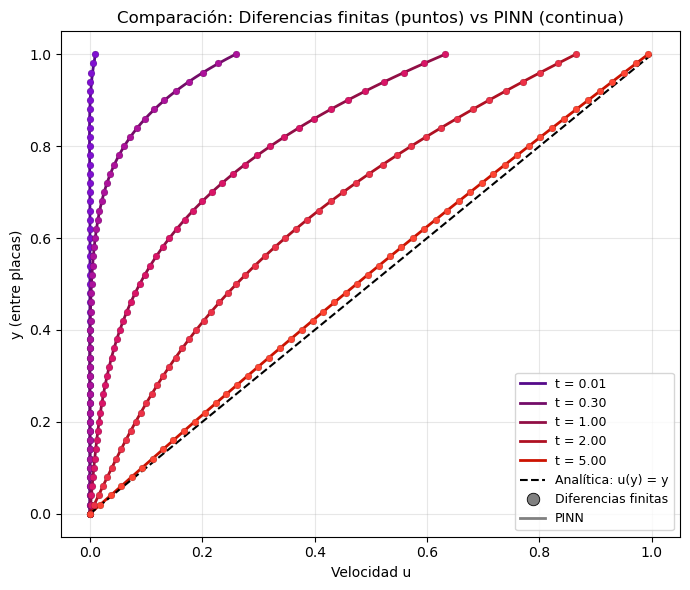

In [58]:
import colorsys
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

t_vals = [0.01, 0.3, 1.0, 2.0, T_MAX]

# Paleta pastel base — un tono por cada instante t
pastel_base = ['#FF9AA2', '#FFB347', '#A8E6CF', '#90CAF9', '#C39BD3']

def variante(hex_color, factor):
    """Aclara (factor>1) u oscurece (factor<1) un color manteniendo el tono (hue)."""
    r, g, b = mcolors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    l = max(0, min(1, l * factor))
    return colorsys.hls_to_rgb(h, l, s)

cmap_morado_rojo = LinearSegmentedColormap.from_list('morado_rojo', ['#6A0DAD', '#FF1600'])
base_colors = cmap_morado_rojo(np.linspace(0, 1, len(t_vals)))

colors_fd   = [variante(c, 1.20) for c in base_colors]   # más claro  -> diferencias finitas
colors_pinn = [variante(c, 0.80) for c in base_colors]   # más oscuro -> PINN (mismo tono)

plt.figure(figsize=(7, 6))
for t_val, c_fd, c_pinn in zip(t_vals, colors_fd, colors_pinn):
    # --- Diferencias finitas (puntos gordos) ---
    n_fd = min(int(round(t_val / dt)), uf.shape[0] - 1)
    plt.plot(uf[n_fd], y, linestyle='none', marker='o', markersize=5,
              markeredgecolor='black', markeredgewidth=0.1, color=c_fd, zorder=3)

    # --- PINN (línea continua) ---
    t_arr  = np.full_like(y_test, t_val)
    u_pred = solution(y_test, t_arr, to_numpy=True).flatten()
    plt.plot(u_pred, y_test, linestyle='-', linewidth=2, color=c_pinn, label=f't = {t_val:.2f}', zorder=2)

# Solución analítica estacionaria
plt.plot(y_test, y_test, 'k--', linewidth=1.5, label='Analítica: u(y) = y')

# Leyenda: colores = tiempos, estilo de línea = método
handles, labels = plt.gca().get_legend_handles_labels()
style_handles = [
    Line2D([0], [0], color='gray', marker='o', linestyle='none', markersize=9,
           markeredgecolor='black', markeredgewidth=0.6, label='Diferencias finitas'),
    Line2D([0], [0], color='gray', linestyle='-', linewidth=2, label='PINN'),
]
plt.legend(handles=handles + style_handles, loc='lower right', fontsize=9)

plt.xlabel('Velocidad u')
plt.ylabel('y (entre placas)')
plt.title('Comparación: Diferencias finitas (puntos) vs PINN (continua)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()